**Human Movement Intelligence | Multimodal Movement Learning | Presented by: Reza Saadatyar (2026)**

**03 | Participant-Grouped Unimodal Movement Classification**

![Source-aligned sEMG and acceleration, classical baselines, CNN/TCN/BiGRU encoders and grouped Development evaluation](../../images/03_unimodal_grouped_baselines.svg)

**Research question:** How do sEMG-only and acceleration-only classical and temporal classifiers compare when evaluated on the same previously unseen Development participants?

**Inputs:** The fixed NinaPro DB2 E1 **40,000 paired windows** from Notebook 02, with **35 Development participants (35,000 windows)** and **five reserved Test participants**. Each observation has one of **18 original corrected source labels (0–17)**.

**Study design:** Five participant-disjoint Development folds evaluate a majority-prior baseline, two Logistic Regression models, two Random Forest models and six 1D-CNN/TCN/BiGRU unimodal architectures. Feature scaling and neural early stopping use permitted Training participants only.

**Primary metric:** Macro F1 is calculated with the fixed 18-class label set for each Validation participant, then averaged **equally across people**. Results from the same Development folds support model selection; they are not an independent final Test estimate.


**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path
import subprocess

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")
if not repo_path.exists():
    subprocess.run(["git", "clone", "-q", repo_url, str(repo_path)], check=True)

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content/human-movement-intelligence


**01. Imports and Research Environment**

In [2]:
# =================== 01. Imports and Research Environment ====================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("multimodal_movement_learning")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab

plot_style(
    font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11,
    legend_size=10, figure_dpi=100, figure_size=(9, 4),
)

# -------------------- 4. Deep Learning and Compute Device --------------------
from core.computer_device import computer_device
device = computer_device(min_vram_gb=None)

# ------------------------ 5. Study Research Utilities ------------------------
from ninapro_dataset import ensure_numerical_cache
from ninapro_evaluation import select_model, predictions_from_probabilities
from ninapro_models import UNIMODAL_MODELS
from ninapro_experiments import (
    CLASSICAL_MODELS, run_classical_arm, run_unimodal_arm,
    consolidate_unimodal_outputs, evaluate_finalist_seeds,
    consolidate_seed_robustness,
)

# ---------------------- 6. Source and Output Locations -----------------------
study_dir = root / "multimodal_movement_learning"
output_dir = study_dir / "output"
processed_dir = root / "data" / "processed" / "ninapro_db2"
output_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)
print("Research output directory:", output_dir)


Repository up to date.
Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.14.1+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92800
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Research output directory: /content/human-movement-intelligence/multimodal_movement_learning/output


**02. Read Fixed Classes and Paired Development Windows**

Read the window identities, corrected source labels and participant assignments established in Notebook 02. The reserved five Test participants are excluded before any model fitting; all eleven models are assessed on the same five Development validation folds.

The Training and Validation partitions never share a participant, even though adjacent windows may overlap within an individual source recording.


In [3]:
# =========== 02. Read Fixed Classes and Paired Development Windows ===========

NOTEBOOK_NUMBER = 3
index = pd.read_csv(output_dir / "02_window_index.csv")
roles = pd.read_csv(output_dir / "02_participant_split_assignments.csv")
folds = pd.read_csv(output_dir / "02_development_fold_assignments.csv")
classes = np.sort(pd.read_csv(output_dir / "01_label_dictionary.csv").label.to_numpy(int))
role_map = dict(zip(roles.subject_id, roles.role))
fold_map = dict(zip(folds.subject_id, folds.validation_fold))
index["role"] = index.subject_id.map(role_map)
index["validation_fold"] = index.subject_id.map(fold_map)
if index.role.isna().any() or index.loc[index.role == "Development", "validation_fold"].isna().any():
    raise ValueError("Incomplete Notebook 02 person/fold assignments.")

dev = index.loc[index.role == "Development"].copy()
assert not set(dev.subject_id) & set(roles.loc[roles.role == "Test", "subject_id"])
print("Development people:", dev.subject_id.nunique(), "| windows:", len(dev))
print("Independent Development folds:", sorted(dev.validation_fold.unique()))


Development people: 35 | windows: 35000
Independent Development folds: [np.float64(0.0), np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(4.0)]


**03. Recover Aligned Statistical and Temporal Inputs**

Reuse the paired numerical representations established in Notebook 02: **48 statistical sEMG features** and **96 acceleration features** per window, together with the **600-row temporal recordings** required by the CNN, TCN and BiGRU models.

The input routine validates the paired sensor arrays and statistical features. Existing compatible files are reused; unavailable inputs are reconstructed from the local source archives or retrieved when permitted. Console messages summarise data preparation or confirm feature reuse without exposing per-participant cache details.

Both modalities retain the same canonical `window_row` ordering. Feature scaling and neural normalisation are fitted **within Training participants** at the model-fitting procedure; no global cohort-level scaler is fitted here.


In [4]:
# ============ 03. Recover Aligned Statistical and Temporal Inputs ============

emg_features, acc_features = ensure_numerical_cache(
    root, index, allow_source_download=True, verbose=True,
)
print("Feature array shapes:", emg_features.shape, acc_features.shape)
print("Fixed task classes:", classes.tolist())


Preparing paired sEMG and acceleration recordings...
Paired recordings ready for 40 participants.
Extracting statistical features from the paired windows...
Saved statistical features (55.7 s).
Feature array shapes: (40000, 48) (40000, 96)
Fixed task classes: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]


**04. Shared Development Protocol**

All eleven models use corrected E1 labels, the same five participant-disjoint Development folds and primary seed `42`. Classical feature scaling and neural channel normalisation are fitted on permitted Training participants. Neural checkpoints use an inner holdout drawn from those Training participants, not the outer Validation group.

Each model produces fold-specific out-of-fold (OOF) probabilities and participant-level metrics. Unimodal sEMG and acceleration models read only their corresponding source channels. On CUDA, the streamed loader supports parallel prefetching; acceleration-only models also prepare normalised fold-specific windows in GPU memory when capacity permits. The same original paired windows, model definitions and training budgets are retained.


In [5]:
# ====================== 04. Shared Development Protocol ======================

SEED = 42
NEURAL_EPOCHS = 10
NEURAL_PATIENCE = 3
NEURAL_BATCH_SIZE = 96
common_folds = sorted(dev.validation_fold.dropna().unique().astype(int).tolist())

print("Classical models:", ", ".join(CLASSICAL_MODELS))
print("Neural models:", ", ".join(UNIMODAL_MODELS))
print("Grouped Development folds:", common_folds)
print("Training epochs (maximum):", NEURAL_EPOCHS)


Classical models: B0_prior, B1_logreg, B1_rf, B2_logreg, B2_rf
Neural models: D1_emg_cnn, D1_acc_cnn, D2_emg_tcn, D2_acc_tcn, D3_emg_bigru, D3_acc_bigru
Grouped Development folds: [0, 1, 2, 3, 4]
Training epochs (maximum): 10


**05. B0: Training-Prior Baseline**

This no-signal reference estimates class priors from Training labels and predicts without using either sensor. Its fold-wise macro F1 provides a necessary baseline for interpreting sensor-dependent performance; it does not represent a clinical or movement-aware classifier.


In [6]:
# ====================== 05. B0: Training-Prior Baseline ======================

# Participant-Grouped Model Fit
display(run_classical_arm(
    "B0_prior", dev, emg_features, acc_features, classes,
    output_dir=output_dir, folds=common_folds, seed=SEED,
))



Model: B0_prior | modality: Training prior | 5 independent Development folds
  Fold 1/5 | 7 validation people | mean participant macro F1 0.0335 | 0.0 s
  Fold 2/5 | 7 validation people | mean participant macro F1 0.0376 | 0.0 s
  Fold 3/5 | 7 validation people | mean participant macro F1 0.0329 | 0.0 s
  Fold 4/5 | 7 validation people | mean participant macro F1 0.0349 | 0.0 s
  Fold 5/5 | 7 validation people | mean participant macro F1 0.0360 | 0.0 s
B0_prior | equal-participant Development macro F1: 0.0350


,validation_fold,participants,macro_f1,fit_seconds
0,0,7,0.033499,0.014964
1,1,7,0.037590,0.007171
2,2,7,0.032872,0.007521
3,3,7,0.034879,0.006360
4,4,7,0.036016,0.007172


**06. B1: sEMG Logistic Regression**

Logistic Regression uses the **48 sEMG statistical features** with a Training-fitted standard scaler and balanced class weights. The `lbfgs` solver must reach numerical convergence before its predictions enter the Development comparison. The number of solver iterations is recorded per fold.


In [7]:
# ===================== 06. B1: sEMG Logistic Regression ======================

#  Participant-Grouped Model Fit
display(run_classical_arm(
    "B1_logreg", dev, emg_features, acc_features, classes,
    output_dir=output_dir, folds=common_folds, seed=SEED,
))



Model: B1_logreg | modality: sEMG | 5 independent Development folds
  Fold 1/5 | 7 validation people | mean participant macro F1 0.1575 | 16.5 s | converged in 317 iterations
  Fold 2/5 | 7 validation people | mean participant macro F1 0.1902 | 15.6 s | converged in 285 iterations
  Fold 3/5 | 7 validation people | mean participant macro F1 0.2254 | 15.3 s | converged in 301 iterations
  Fold 4/5 | 7 validation people | mean participant macro F1 0.2531 | 17.0 s | converged in 308 iterations
  Fold 5/5 | 7 validation people | mean participant macro F1 0.2159 | 16.9 s | converged in 299 iterations
B1_logreg | equal-participant Development macro F1: 0.2084


,validation_fold,participants,macro_f1,fit_seconds,solver_iterations
0,0,7,0.157546,16.485226,317
1,1,7,0.190164,15.628653,285
2,2,7,0.225351,15.319244,301
3,3,7,0.253074,16.992258,308
4,4,7,0.215921,16.857895,299


**07. B1: sEMG Random Forest**

The 48-feature sEMG representation is assessed using a class-weighted 120-tree Random Forest. The source windows and independent participant folds are identical to those used by Logistic Regression; no Test data contribute to fitting or comparison.


In [8]:
# ======================== 07. B1: sEMG Random Forest =========================

# Participant-Grouped Model Fit
display(run_classical_arm(
    "B1_rf", dev, emg_features, acc_features, classes,
    output_dir=output_dir, folds=common_folds, seed=SEED,
))



Model: B1_rf | modality: sEMG | 5 independent Development folds
  Fold 1/5 | 7 validation people | mean participant macro F1 0.1794 | 38.0 s
  Fold 2/5 | 7 validation people | mean participant macro F1 0.2576 | 37.2 s
  Fold 3/5 | 7 validation people | mean participant macro F1 0.2481 | 36.7 s
  Fold 4/5 | 7 validation people | mean participant macro F1 0.2541 | 34.0 s
  Fold 5/5 | 7 validation people | mean participant macro F1 0.2350 | 36.3 s
B1_rf | equal-participant Development macro F1: 0.2348


,validation_fold,participants,macro_f1,fit_seconds
0,0,7,0.179359,37.991971
1,1,7,0.257636,37.232288
2,2,7,0.248078,36.737813
3,3,7,0.254077,33.962853
4,4,7,0.235029,36.344715


**08. B2: Acceleration Logistic Regression**

The acceleration-only Logistic Regression receives the **96 statistical acceleration features**. It uses the same regularisation, numerical convergence checks, Training-only standardisation and grouped folds as the sEMG variant.


In [9]:
# ================= 08. B2: Acceleration Logistic Regression ==================

# Participant-Grouped Model Fit
display(run_classical_arm(
    "B2_logreg", dev, emg_features, acc_features, classes,
    output_dir=output_dir, folds=common_folds, seed=SEED,
))



Model: B2_logreg | modality: Acceleration | 5 independent Development folds
  Fold 1/5 | 7 validation people | mean participant macro F1 0.0767 | 32.8 s | converged in 523 iterations
  Fold 2/5 | 7 validation people | mean participant macro F1 0.0833 | 37.5 s | converged in 543 iterations
  Fold 3/5 | 7 validation people | mean participant macro F1 0.0915 | 38.6 s | converged in 539 iterations
  Fold 4/5 | 7 validation people | mean participant macro F1 0.1472 | 37.5 s | converged in 517 iterations
  Fold 5/5 | 7 validation people | mean participant macro F1 0.1186 | 34.3 s | converged in 509 iterations
B2_logreg | equal-participant Development macro F1: 0.1034


,validation_fold,participants,macro_f1,fit_seconds,solver_iterations
0,0,7,0.076674,32.843143,523
1,1,7,0.083292,37.480152,543
2,2,7,0.091470,38.560505,539
3,3,7,0.147195,37.497748,517
4,4,7,0.118580,34.310567,509


**09. B2: Acceleration Random Forest**

A 120-tree Random Forest uses only the acceleration feature matrix. Its validation participants, scoring classes and metric aggregation are unchanged, so modality comparisons do not depend on different data partitions.


In [10]:
# ==================== 09. B2: Acceleration Random Forest =====================

# Participant-Grouped Model Fit 
display(run_classical_arm(
    "B2_rf", dev, emg_features, acc_features, classes,
    output_dir=output_dir, folds=common_folds, seed=SEED,
))



Model: B2_rf | modality: Acceleration | 5 independent Development folds
  Fold 1/5 | 7 validation people | mean participant macro F1 0.1308 | 56.0 s
  Fold 2/5 | 7 validation people | mean participant macro F1 0.1144 | 54.7 s
  Fold 3/5 | 7 validation people | mean participant macro F1 0.1326 | 53.7 s
  Fold 4/5 | 7 validation people | mean participant macro F1 0.1319 | 56.0 s
  Fold 5/5 | 7 validation people | mean participant macro F1 0.1353 | 52.6 s
B2_rf | equal-participant Development macro F1: 0.1290


,validation_fold,participants,macro_f1,fit_seconds
0,0,7,0.130753,55.963994
1,1,7,0.114388,54.711611
2,2,7,0.132585,53.679570
3,3,7,0.131860,55.969480
4,4,7,0.135303,52.573977


**10. D1: sEMG-Only 1D-CNN**

A compact three-layer 1D-CNN learns local temporal patterns from the **12 sEMG channels**. Its Training-only inner holdout selects the checkpoint; each outer fold reports seven independent Validation participants. Acceleration is excluded from its predictive inputs.



Model: D1_emg_cnn | modality: sEMG | device: cuda | 5 independent Development folds

  Fold 1/5 | 28 Training, 7 Validation people
  Data loader: emg only | streamed | workers=2 | pinned memory=True | batch size=96
  D1_emg_cnn | seed=42 | epoch 1/10 | loss=2.5883 | inner macro F1=0.1928 | train=15.9 s | inner validation=1.5 s | total=17.4 s
  D1_emg_cnn | seed=42 | epoch 2/10 | loss=2.3447 | inner macro F1=0.2081 | train=3.9 s | inner validation=0.4 s | total=4.2 s
  D1_emg_cnn | seed=42 | epoch 3/10 | loss=2.2486 | inner macro F1=0.2313 | train=2.7 s | inner validation=0.4 s | total=3.0 s
  D1_emg_cnn | seed=42 | epoch 4/10 | loss=2.1868 | inner macro F1=0.2472 | train=2.6 s | inner validation=0.3 s | total=3.0 s
  D1_emg_cnn | seed=42 | epoch 5/10 | loss=2.1369 | inner macro F1=0.2523 | train=2.7 s | inner validation=0.4 s | total=3.0 s
  D1_emg_cnn | seed=42 | epoch 6/10 | loss=2.0982 | inner macro F1=0.2572 | train=4.0 s | inner validation=0.4 s | total=4.3 s
  D1_emg_cnn | seed=

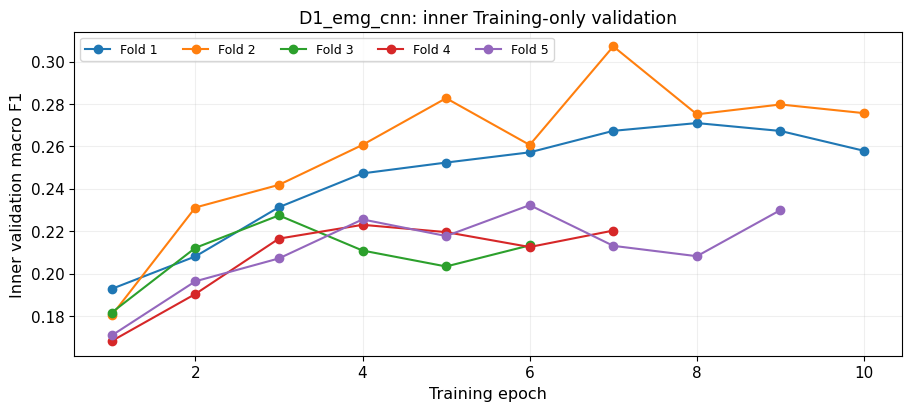

,validation_fold,participants,macro_f1,best_epoch,fit_seconds
0,0,7,0.174568,8,48.499626
1,1,7,0.213109,7,34.006701
2,2,7,0.221538,3,20.484666
3,3,7,0.262827,4,24.733800
4,4,7,0.218836,6,32.484659


In [11]:
# ========================= 10. D1: sEMG-Only 1D-CNN ==========================

# Participant-Grouped Model Fit
display(run_unimodal_arm(
    "D1_emg_cnn", dev, processed_dir, classes, output_dir=output_dir,
    folds=common_folds, device=device, seed=SEED,
    epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**11. D1: Acceleration-Only 1D-CNN**

The matched 1D-CNN receives **36 acceleration columns** on the released common sample-row grid. The original acceleration acquisition rate was lower than the stored grid rate, so adjacent interpolated rows are not independent high-rate sensor measurements.

For CUDA training, normalised acceleration windows from the permitted Training participants are placed in GPU memory once per fold when sufficient memory is available. Each epoch reuses those windows without rereading the original arrays. The streamed loader remains available when GPU memory is insufficient. This affects computational throughput, not the selected windows or model capacity.



Model: D1_acc_cnn | modality: Acceleration | device: cuda | 5 independent Development folds

  Fold 1/5 | 28 Training, 7 Validation people
  Acceleration cache: staging 2.25 GiB of Training-only normalised windows on CUDA...
  Acceleration cache ready in 29.1 s; reused across all epochs of this fold.
  Data loader: acc only | GPU-cached | workers=0 | pinned memory=False | batch size=96
  D1_acc_cnn | seed=42 | epoch 1/10 | loss=2.3363 | inner macro F1=0.0735 | train=0.9 s | inner validation=0.0 s | total=1.0 s
  D1_acc_cnn | seed=42 | epoch 2/10 | loss=1.8135 | inner macro F1=0.0536 | train=0.9 s | inner validation=0.0 s | total=0.9 s
  D1_acc_cnn | seed=42 | epoch 3/10 | loss=1.5659 | inner macro F1=0.0487 | train=0.8 s | inner validation=0.0 s | total=0.9 s
  D1_acc_cnn | seed=42 | epoch 4/10 | loss=1.4160 | inner macro F1=0.0674 | train=1.0 s | inner validation=0.1 s | total=1.0 s
  Fold 1 completed | participant-mean macro F1 0.0622 | best epoch 1 | fit 3.8 s

  Fold 2/5 | 28 Trai

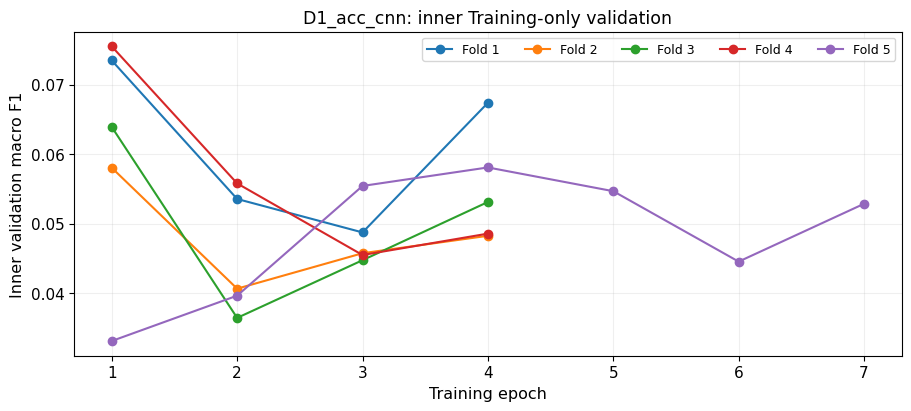

,validation_fold,participants,macro_f1,best_epoch,fit_seconds
0,0,7,0.062200,1,3.842104
1,1,7,0.053177,1,3.592985
2,2,7,0.081095,1,3.723847
3,3,7,0.080828,1,3.653568
4,4,7,0.060078,4,7.080907


In [12]:
# ===================== 11. D1: Acceleration-Only 1D-CNN ======================

# Participant-Grouped Model Fit
display(run_unimodal_arm(
    "D1_acc_cnn", dev, processed_dir, classes, output_dir=output_dir,
    folds=common_folds, device=device, seed=SEED,
    epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**12. D2: sEMG-Only Temporal CNN**

The residual temporal convolutional network uses dilated convolutional blocks on sEMG. It is compared against the other encoders on the same retained windows, common folds, training budget and fixed label definitions.



Model: D2_emg_tcn | modality: sEMG | device: cuda | 5 independent Development folds

  Fold 1/5 | 28 Training, 7 Validation people
  Data loader: emg only | streamed | workers=2 | pinned memory=True | batch size=96
  D2_emg_tcn | seed=42 | epoch 1/10 | loss=2.5353 | inner macro F1=0.2012 | train=19.9 s | inner validation=1.4 s | total=21.4 s
  D2_emg_tcn | seed=42 | epoch 2/10 | loss=2.2665 | inner macro F1=0.1894 | train=3.6 s | inner validation=0.4 s | total=4.0 s
  D2_emg_tcn | seed=42 | epoch 3/10 | loss=2.1807 | inner macro F1=0.2227 | train=4.7 s | inner validation=0.4 s | total=5.1 s
  D2_emg_tcn | seed=42 | epoch 4/10 | loss=2.1108 | inner macro F1=0.2243 | train=3.5 s | inner validation=0.4 s | total=3.9 s
  D2_emg_tcn | seed=42 | epoch 5/10 | loss=2.0389 | inner macro F1=0.2318 | train=3.4 s | inner validation=0.4 s | total=3.8 s
  D2_emg_tcn | seed=42 | epoch 6/10 | loss=1.9955 | inner macro F1=0.2318 | train=4.8 s | inner validation=0.4 s | total=5.3 s
  D2_emg_tcn | seed=

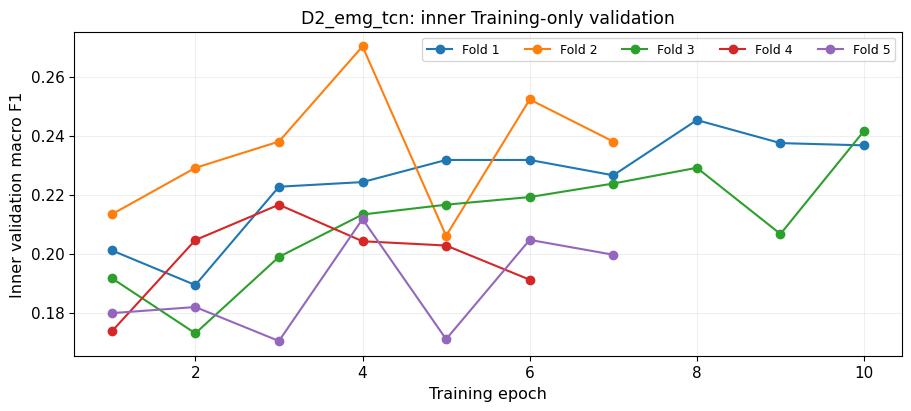

,validation_fold,participants,macro_f1,best_epoch,fit_seconds
0,0,7,0.169830,8,60.345012
1,1,7,0.199970,4,31.292788
2,2,7,0.226022,10,42.095456
3,3,7,0.239293,3,25.277398
4,4,7,0.229003,4,30.004391


In [13]:
# ====================== 12. D2: sEMG-Only Temporal CNN =======================

# Participant-Grouped Model Fit
display(run_unimodal_arm(
    "D2_emg_tcn", dev, processed_dir, classes, output_dir=output_dir,
    folds=common_folds, device=device, seed=SEED,
    epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**13. D2: Acceleration-Only Temporal CNN**

The same residual TCN family processes the source-aligned acceleration sequence. Reporting fold-specific training times makes any modality-dependent runtime costs visible without changing the participant-independent evaluation.



Model: D2_acc_tcn | modality: Acceleration | device: cuda | 5 independent Development folds

  Fold 1/5 | 28 Training, 7 Validation people
  Acceleration cache: staging 2.25 GiB of Training-only normalised windows on CUDA...
  Acceleration cache ready in 27.9 s; reused across all epochs of this fold.
  Data loader: acc only | GPU-cached | workers=0 | pinned memory=False | batch size=96
  D2_acc_tcn | seed=42 | epoch 1/10 | loss=2.1655 | inner macro F1=0.0592 | train=1.6 s | inner validation=0.1 s | total=1.7 s
  D2_acc_tcn | seed=42 | epoch 2/10 | loss=1.6076 | inner macro F1=0.0591 | train=1.6 s | inner validation=0.1 s | total=1.7 s
  D2_acc_tcn | seed=42 | epoch 3/10 | loss=1.4311 | inner macro F1=0.0812 | train=1.6 s | inner validation=0.1 s | total=1.7 s
  D2_acc_tcn | seed=42 | epoch 4/10 | loss=1.2882 | inner macro F1=0.0604 | train=1.6 s | inner validation=0.1 s | total=1.7 s
  D2_acc_tcn | seed=42 | epoch 5/10 | loss=1.1928 | inner macro F1=0.0591 | train=1.6 s | inner valida

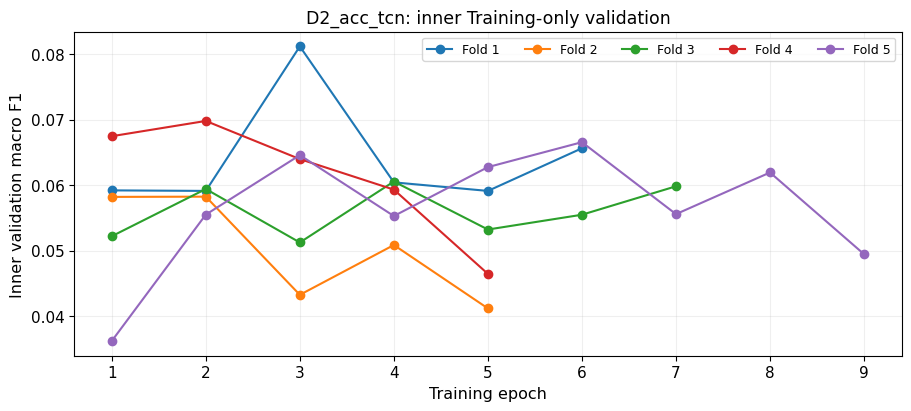

,validation_fold,participants,macro_f1,best_epoch,fit_seconds
0,0,7,0.059362,3,10.312258
1,1,7,0.060793,2,8.735374
2,2,7,0.073414,4,12.466251
3,3,7,0.077606,2,8.652979
4,4,7,0.083467,6,15.686992


In [14]:
# ================== 13. D2: Acceleration-Only Temporal CNN ===================

# 1. Participant-Grouped Model Fit
display(run_unimodal_arm(
    "D2_acc_tcn", dev, processed_dir, classes, output_dir=output_dir,
    folds=common_folds, device=device, seed=SEED,
    epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**14. D3: sEMG-Only BiGRU**

The bidirectional gated recurrent network models temporal dependencies after pooling the sEMG time axis. Bidirectionality uses the complete offline window; it does not demonstrate causal or real-time operation.



Model: D3_emg_bigru | modality: sEMG | device: cuda | 5 independent Development folds

  Fold 1/5 | 28 Training, 7 Validation people
  Data loader: emg only | streamed | workers=2 | pinned memory=True | batch size=96
  D3_emg_bigru | seed=42 | epoch 1/10 | loss=2.7843 | inner macro F1=0.1383 | train=21.1 s | inner validation=1.4 s | total=22.5 s
  D3_emg_bigru | seed=42 | epoch 2/10 | loss=2.5148 | inner macro F1=0.1876 | train=3.4 s | inner validation=0.4 s | total=3.9 s
  D3_emg_bigru | seed=42 | epoch 3/10 | loss=2.4304 | inner macro F1=0.1982 | train=4.2 s | inner validation=0.7 s | total=4.9 s
  D3_emg_bigru | seed=42 | epoch 4/10 | loss=2.3776 | inner macro F1=0.1996 | train=3.7 s | inner validation=0.5 s | total=4.1 s
  D3_emg_bigru | seed=42 | epoch 5/10 | loss=2.3369 | inner macro F1=0.2013 | train=3.3 s | inner validation=0.4 s | total=3.8 s
  D3_emg_bigru | seed=42 | epoch 6/10 | loss=2.3059 | inner macro F1=0.2100 | train=3.5 s | inner validation=0.7 s | total=4.2 s
  D3_e

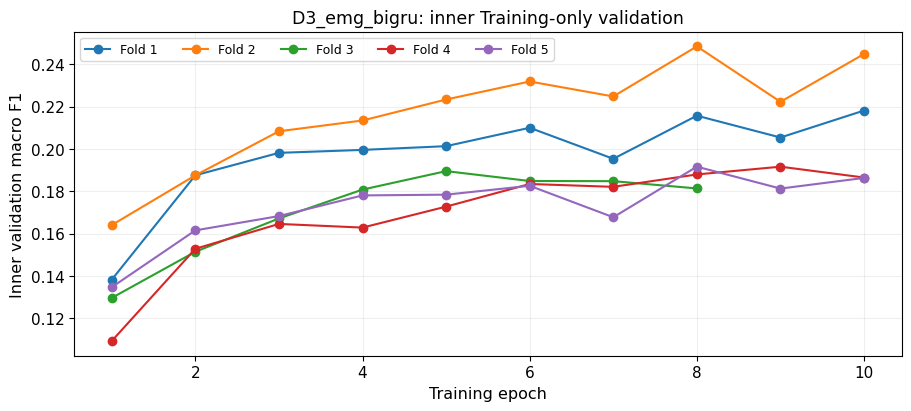

,validation_fold,participants,macro_f1,best_epoch,fit_seconds
0,0,7,0.140989,10,60.953855
1,1,7,0.192177,8,42.237185
2,2,7,0.178834,5,32.702210
3,3,7,0.226029,9,39.936152
4,4,7,0.198770,8,39.417950


In [15]:
# ========================== 14. D3: sEMG-Only BiGRU ==========================

# Participant-Grouped Model Fit
display(run_unimodal_arm(
    "D3_emg_bigru", dev, processed_dir, classes, output_dir=output_dir,
    folds=common_folds, device=device, seed=SEED,
    epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**15. D3: Acceleration-Only BiGRU**

The acceleration BiGRU completes the six unimodal temporal comparisons. Predictions are evaluated on the same seven unseen Development participants in each fold; its probabilities and participant-level scores enter the common model comparison.



Model: D3_acc_bigru | modality: Acceleration | device: cuda | 5 independent Development folds

  Fold 1/5 | 28 Training, 7 Validation people
  Acceleration cache: staging 2.25 GiB of Training-only normalised windows on CUDA...
  Acceleration cache ready in 27.5 s; reused across all epochs of this fold.
  Data loader: acc only | GPU-cached | workers=0 | pinned memory=False | batch size=96
  D3_acc_bigru | seed=42 | epoch 1/10 | loss=2.6973 | inner macro F1=0.0600 | train=0.9 s | inner validation=0.0 s | total=0.9 s
  D3_acc_bigru | seed=42 | epoch 2/10 | loss=2.3523 | inner macro F1=0.0574 | train=0.9 s | inner validation=0.0 s | total=1.0 s
  D3_acc_bigru | seed=42 | epoch 3/10 | loss=2.0686 | inner macro F1=0.0480 | train=0.9 s | inner validation=0.0 s | total=1.0 s
  D3_acc_bigru | seed=42 | epoch 4/10 | loss=1.9069 | inner macro F1=0.0570 | train=1.0 s | inner validation=0.0 s | total=1.0 s
  Fold 1 completed | participant-mean macro F1 0.0616 | best epoch 1 | fit 3.9 s

  Fold 2/5

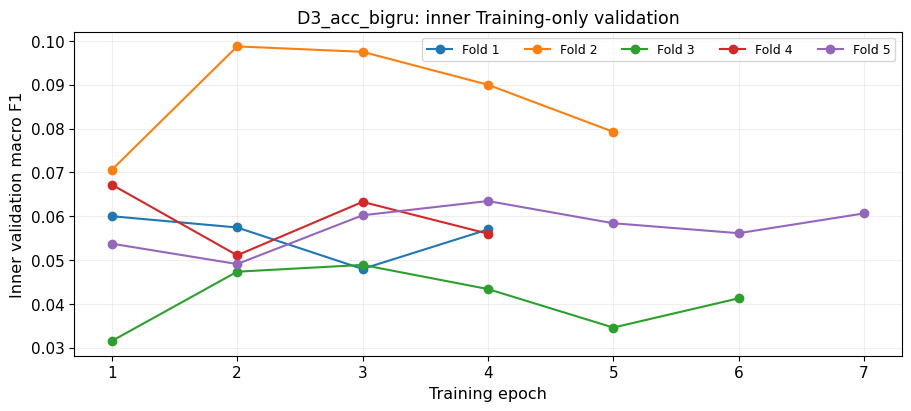

,validation_fold,participants,macro_f1,best_epoch,fit_seconds
0,0,7,0.061583,1,3.859160
1,1,7,0.059760,2,4.847165
2,2,7,0.076771,3,6.378192
3,3,7,0.064374,1,3.617432
4,4,7,0.065204,4,6.541115


In [16]:
# ====================== 15. D3: Acceleration-Only BiGRU ======================

# Participant-Grouped Model Fit 
display(run_unimodal_arm(
    "D3_acc_bigru", dev, processed_dir, classes, output_dir=output_dir,
    folds=common_folds, device=device, seed=SEED,
    epochs=NEURAL_EPOCHS, patience=NEURAL_PATIENCE,
    batch_size=NEURAL_BATCH_SIZE, figure_save=save_figure,
))


**16. Consolidate Development Experiments**

Load the model-specific OOF probabilities, predictions and participant-level metrics, retaining the original source-window identities, class order, seed and fold assignment. Five Development validation folds provide matched evidence for comparing all eleven models.

The full-length probability arrays are indexed by the original `window_row`. Development rows contain OOF predictions; reserved Test rows remain unpopulated. The reference unimodal model is selected using the mean fixed-class macro F1 across 35 Development participants, each with equal weight.


In [17]:
# ================== 16. Consolidate Development Experiments ==================

probabilities, classical_metrics, neural_metrics, neural_history, chosen, summary = (
    consolidate_unimodal_outputs(
        index, dev, classes, output_dir=output_dir, folds=common_folds,
        seed=SEED, neural_settings={
            "epochs": NEURAL_EPOCHS,
            "patience": NEURAL_PATIENCE,
            "batch_size": NEURAL_BATCH_SIZE,
        },
    )
)
print("Development-selected unimodal comparator:", chosen)
display(summary)


Loaded B0_prior: 35 Development people
Loaded B1_logreg: 35 Development people
Loaded B1_rf: 35 Development people
Loaded B2_logreg: 35 Development people
Loaded B2_rf: 35 Development people
Loaded D1_emg_cnn: 35 Development people
Loaded D1_acc_cnn: 35 Development people
Loaded D2_emg_tcn: 35 Development people
Loaded D2_acc_tcn: 35 Development people
Loaded D3_emg_bigru: 35 Development people
Loaded D3_acc_bigru: 35 Development people
Development-selected unimodal comparator: B1_rf


,model_id,mean_subject_macro_f1,subjects
0,B1_rf,0.234836,35
1,D1_emg_cnn,0.218176,35
2,D2_emg_tcn,0.212824,35
3,B1_logreg,0.208411,35
4,D3_emg_bigru,0.187360,35
5,B2_rf,0.128978,35
6,B2_logreg,0.103442,35
7,D2_acc_tcn,0.070928,35
8,D1_acc_cnn,0.067476,35
9,D3_acc_bigru,0.065538,35


**17. Select Neural Finalists for Seed Robustness**

Choose one neural model independently within each modality using Development participant-mean macro F1. Training seeds **43** and **44** repeat each selected model on the same grouped folds; these repeated fits are secondary stability evidence and must not be treated as additional independent participants.


In [18]:
# ================== 17. Select Neural Robustness Finalists ===================

EXTRA_SEEDS = (43, 44)
emg_finalist, _ = select_model(
    neural_metrics, [name for name in UNIMODAL_MODELS if "_emg_" in name]
)
acc_finalist, _ = select_model(
    neural_metrics, [name for name in UNIMODAL_MODELS if "_acc_" in name]
)
print("sEMG finalist:", emg_finalist)
print("Acceleration finalist:", acc_finalist)


sEMG finalist: D1_emg_cnn
Acceleration finalist: D2_acc_tcn


**18. Additional Seeds: Selected sEMG Model**

Repeat the Development-selected sEMG temporal architecture at seeds 43 and 44. Each run uses the same participant separation and Training-only normalisation; each seed/fold combination is recorded separately for stability analysis.


In [19]:
# ===================== 18. sEMG Finalist Seed Robustness =====================

display(evaluate_finalist_seeds(
    emg_finalist, dev, processed_dir, classes,
    output_dir=output_dir, folds=common_folds, device=device,
    seeds=EXTRA_SEEDS, epochs=NEURAL_EPOCHS,
    patience=NEURAL_PATIENCE, batch_size=NEURAL_BATCH_SIZE,
))



D1_emg_cnn | extra seed 43 | fold 1/5
  Data loader: emg only | streamed | workers=2 | pinned memory=True | batch size=96
  D1_emg_cnn | seed=43 | epoch 1/10 | loss=2.5684 | inner macro F1=0.2210 | train=18.7 s | inner validation=1.5 s | total=20.1 s
  D1_emg_cnn | seed=43 | epoch 2/10 | loss=2.3444 | inner macro F1=0.2362 | train=2.8 s | inner validation=0.4 s | total=3.2 s
  D1_emg_cnn | seed=43 | epoch 3/10 | loss=2.2545 | inner macro F1=0.2142 | train=3.8 s | inner validation=0.3 s | total=4.1 s
  D1_emg_cnn | seed=43 | epoch 4/10 | loss=2.1879 | inner macro F1=0.2427 | train=2.8 s | inner validation=0.3 s | total=3.1 s
  D1_emg_cnn | seed=43 | epoch 5/10 | loss=2.1440 | inner macro F1=0.2609 | train=2.7 s | inner validation=0.3 s | total=3.0 s
  D1_emg_cnn | seed=43 | epoch 6/10 | loss=2.0899 | inner macro F1=0.2475 | train=2.6 s | inner validation=0.3 s | total=3.0 s
  D1_emg_cnn | seed=43 | epoch 7/10 | loss=2.0521 | inner macro F1=0.2371 | train=3.7 s | inner validation=0.4 s 

,seed,participant_mean_macro_f1,fits
0,43,0.213478,5
1,44,0.216074,5


**19. Additional Seeds: Selected Acceleration Model**

Apply the identical two extra seeds to the Development-selected acceleration model. Keep its fold-wise records separate from the sEMG experiment; aggregate the two finalists only after complete seed and fold coverage is verified.


In [20]:
# ================= 19. Acceleration Finalist Seed Robustness =================

display(evaluate_finalist_seeds(
    acc_finalist, dev, processed_dir, classes,
    output_dir=output_dir, folds=common_folds, device=device,
    seeds=EXTRA_SEEDS, epochs=NEURAL_EPOCHS,
    patience=NEURAL_PATIENCE, batch_size=NEURAL_BATCH_SIZE,
))
display(consolidate_seed_robustness(
    (emg_finalist, acc_finalist), output_dir,
    folds=common_folds, seeds=EXTRA_SEEDS,
))



D2_acc_tcn | extra seed 43 | fold 1/5
  Acceleration cache: staging 2.25 GiB of Training-only normalised windows on CUDA...
  Acceleration cache ready in 27.3 s; reused across all epochs of this fold.
  Data loader: acc only | GPU-cached | workers=0 | pinned memory=False | batch size=96
  D2_acc_tcn | seed=43 | epoch 1/10 | loss=2.1448 | inner macro F1=0.0598 | train=1.5 s | inner validation=0.1 s | total=1.6 s
  D2_acc_tcn | seed=43 | epoch 2/10 | loss=1.6311 | inner macro F1=0.0639 | train=1.4 s | inner validation=0.1 s | total=1.5 s
  D2_acc_tcn | seed=43 | epoch 3/10 | loss=1.4237 | inner macro F1=0.0602 | train=1.4 s | inner validation=0.1 s | total=1.5 s
  D2_acc_tcn | seed=43 | epoch 4/10 | loss=1.2960 | inner macro F1=0.0611 | train=1.7 s | inner validation=0.1 s | total=1.8 s
  D2_acc_tcn | seed=43 | epoch 5/10 | loss=1.1967 | inner macro F1=0.0682 | train=1.6 s | inner validation=0.1 s | total=1.7 s
  D2_acc_tcn | seed=43 | epoch 6/10 | loss=1.1083 | inner macro F1=0.0705 | 

,seed,participant_mean_macro_f1,fits
0,43,0.070353,5
1,44,0.074801,5


,model_id,seed,macro_f1
0,D1_emg_cnn,43,0.213478
1,D1_emg_cnn,44,0.216074
2,D2_acc_tcn,43,0.070353
3,D2_acc_tcn,44,0.074801


**20. Compare Unimodal Performance and Class-Level Errors**

The model comparison uses mean participant macro F1 across independent Development participants. Learning-loss curves describe optimisation but are not measures of held-out classification performance.

The class-level analysis reuses the saved OOF probabilities from all eleven models, without refitting any classifier. For every original corrected label, it reports pooled window-level precision, recall and F1, class support, and the corresponding metrics averaged equally across participants. Fixed-class participant averages assign zero to an unsupported class, consistently with the primary macro-F1 definition.

The selected model is shown using both a raw window-count confusion matrix and a row-normalised matrix (proportion within each true class), complemented by an 11-model per-class F1 heatmap. The pooled and participant-mean metrics have different aggregation units. All displays concern Development predictions; the reserved Test participants are excluded.


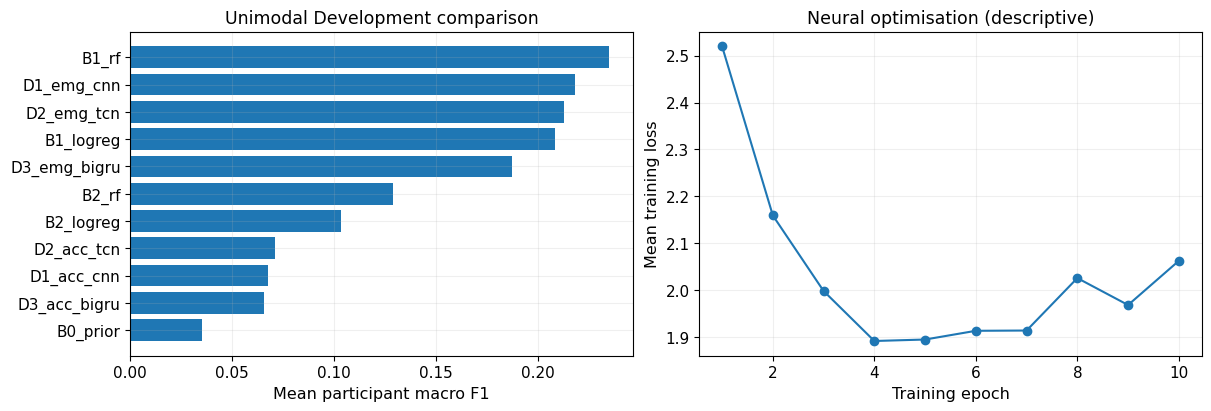

,class_label,support_windows,participants_with_support,pooled_precision,pooled_recall,pooled_f1,mean_participant_recall,mean_participant_f1
0,0,16329,35,0.7034,0.9023,0.7905,0.9082,0.7814
1,1,1464,35,0.2233,0.1844,0.2020,0.1819,0.1780
2,2,1279,35,0.1532,0.0962,0.1182,0.1014,0.0988
3,3,1124,35,0.1269,0.0827,0.1002,0.1010,0.0863
4,4,1098,35,0.1713,0.0729,0.1022,0.0946,0.0864
5,5,1117,35,0.1852,0.0537,0.0833,0.0720,0.0769
6,6,947,35,0.3587,0.3041,0.3291,0.3955,0.3708
7,7,1386,35,0.2982,0.1753,0.2208,0.1682,0.1908
8,8,1087,35,0.0762,0.0221,0.0342,0.0283,0.0314
9,9,1167,35,0.2918,0.3590,0.3219,0.3871,0.3347


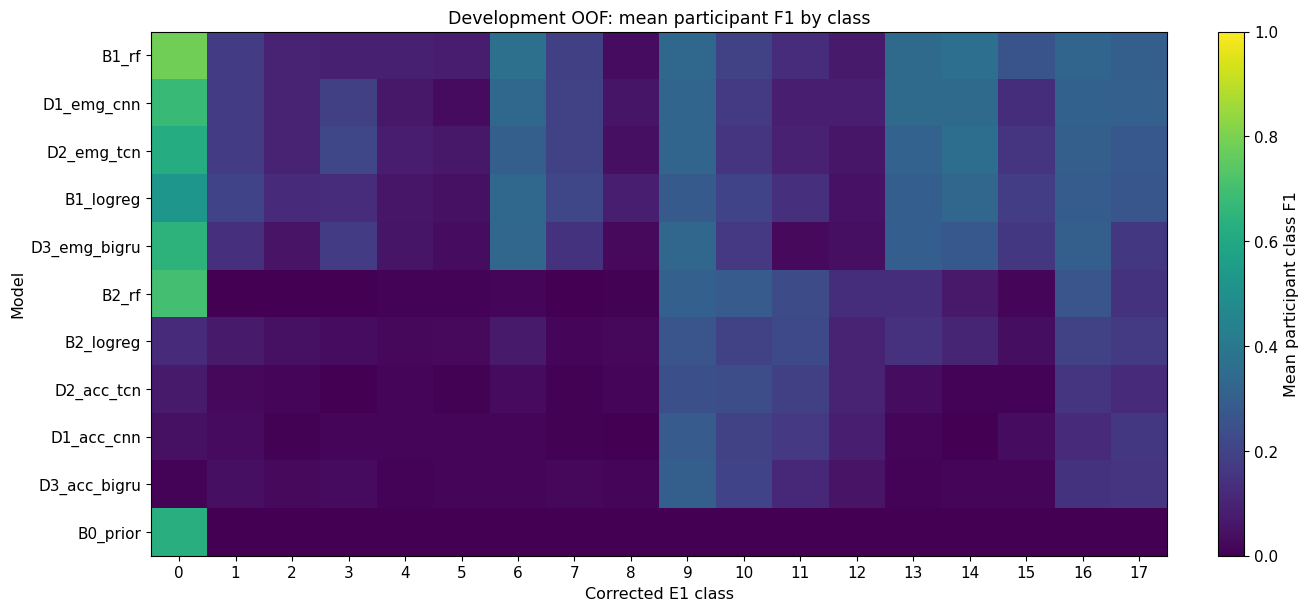

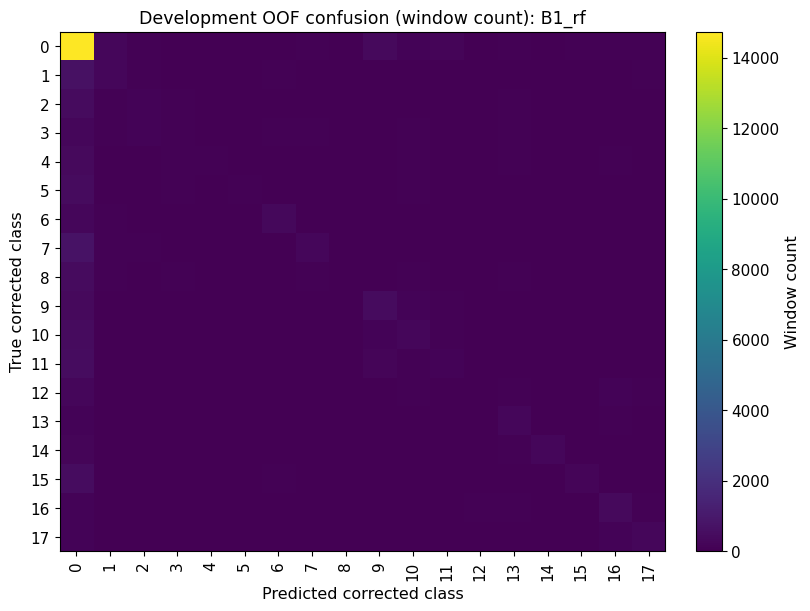

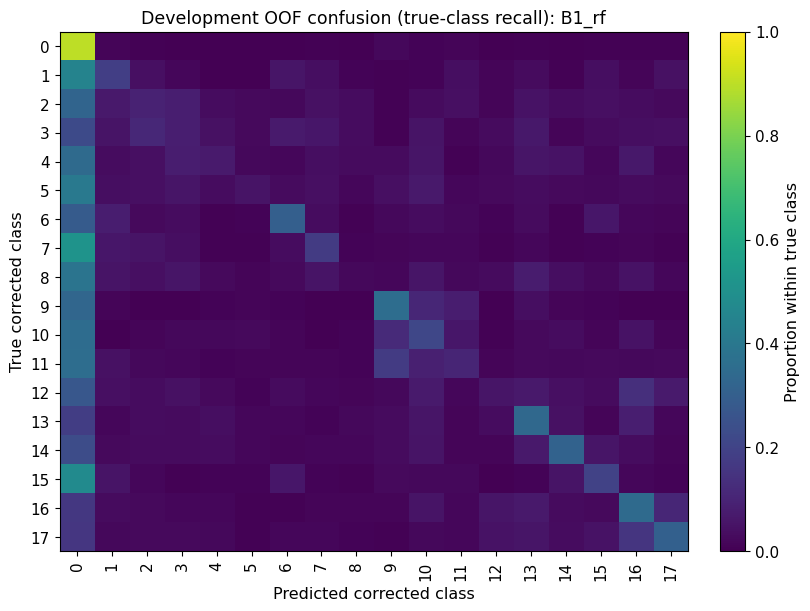

In [ ]:
# ================ 20. Development Comparison and Class Errors ================

# ------------------- 1. Participant-Balanced Model Scores --------------------
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
ranked = summary.iloc[::-1]
axes[0].barh(ranked.model_id, ranked.mean_subject_macro_f1)
axes[0].set(
    xlabel="Mean participant macro F1",
    title="Unimodal Development comparison",
)

# ---------------------- 2. Neural Optimisation History -----------------------
curve = neural_history.groupby("epoch", as_index=False).train_loss.mean()
axes[1].plot(curve.epoch, curve.train_loss, marker="o")
axes[1].set(
    xlabel="Training epoch", ylabel="Mean training loss",
    title="Neural optimisation (descriptive)",
)
for ax in axes:
    ax.grid(alpha=0.2)
save_figure(fig, output_dir / "03_learning_curves.png")
plt.show()

# ------------------------- 3. Per-Class OOF Evidence -------------------------
from ninapro_evaluation import per_class_oof_report

selected_rows = dev.sort_values("window_row").reset_index(drop=True)
window_positions = selected_rows.window_row.to_numpy(int)
all_class_reports = []
for model_name in summary.model_id:
    model_probabilities = probabilities[model_name][window_positions]
    all_class_reports.append(per_class_oof_report(
        selected_rows, model_probabilities, classes, model_id=model_name,
    ))
class_report = pd.concat(all_class_reports, ignore_index=True)
class_report.to_csv(
    output_dir / "03_all_models_per_class_metrics.csv", index=False,
)
selected_class_report = class_report.loc[
    class_report.model_id == chosen
].copy()
selected_class_report.to_csv(
    output_dir / "03_selected_model_per_class_metrics.csv", index=False,
)

# Equal-person class F1 averages reconstruct the original model-selection
# metric; pooled window F1 is a separate descriptive measurement.
expected_score = float(
    summary.set_index("model_id").loc[chosen, "mean_subject_macro_f1"]
)
reported_score = float(selected_class_report.mean_participant_f1.mean())
if not np.isclose(reported_score, expected_score, atol=1e-9):
    raise ValueError("Per-class and participant-level macro F1 disagree.")
display(selected_class_report[[
    "class_label", "support_windows", "participants_with_support",
    "pooled_precision", "pooled_recall", "pooled_f1",
    "mean_participant_recall", "mean_participant_f1",
]].round(4))

# -------------------- 4. Class-Specific F1 Across Models ---------------------
class_grid = (
    class_report.pivot(
        index="model_id", columns="class_label",
        values="mean_participant_f1",
    )
    .reindex(index=summary.model_id, columns=classes)
)
fig, ax = plt.subplots(figsize=(13, 6), layout="constrained")
image = ax.imshow(class_grid.to_numpy(), aspect="auto", vmin=0, vmax=1)
ax.set(
    xlabel="Corrected E1 class", ylabel="Model",
    title="Development OOF: mean participant F1 by class",
)
ax.set_xticks(np.arange(len(classes)), labels=classes)
ax.set_yticks(np.arange(len(class_grid.index)), labels=class_grid.index)
fig.colorbar(image, ax=ax, label="Mean participant class F1")
save_figure(fig, output_dir / "03_per_class_f1_heatmap.png")
plt.show()

# -------------------- 5. Selected-Model Window Confusion ---------------------
selected_probabilities = probabilities[chosen][window_positions]
actual_labels = selected_rows.label.to_numpy(int)
predicted_labels = predictions_from_probabilities(
    selected_probabilities, classes,
)
cm = confusion_matrix(actual_labels, predicted_labels, labels=classes)
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
image = ax.imshow(cm, aspect="auto")
ax.set(
    xlabel="Predicted corrected class", ylabel="True corrected class",
    title=f"Development OOF confusion (window count): {chosen}",
)
ax.set_xticks(np.arange(len(classes)), labels=classes, rotation=90)
ax.set_yticks(np.arange(len(classes)), labels=classes)
fig.colorbar(image, ax=ax, label="Window count")
save_figure(fig, output_dir / "03_class_errors.png")
plt.show()

# ------------------- 6. Within-Class Normalised Confusion --------------------
class_support = cm.sum(axis=1, keepdims=True)
normalised_cm = np.divide(
    cm, class_support, out=np.zeros_like(cm, dtype=float),
    where=class_support > 0,
)
fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
image = ax.imshow(normalised_cm, aspect="auto", vmin=0, vmax=1)
ax.set(
    xlabel="Predicted corrected class", ylabel="True corrected class",
    title=f"Development OOF confusion (true-class recall): {chosen}",
)
ax.set_xticks(np.arange(len(classes)), labels=classes, rotation=90)
ax.set_yticks(np.arange(len(classes)), labels=classes)
fig.colorbar(image, ax=ax, label="Proportion within true class")
save_figure(fig, output_dir / "03_class_errors_normalised.png")
plt.show()


**21. Scientific Interpretation and Research Outputs**

The Development comparison uses the fixed 18-class task, identical participant-disjoint folds, Training-only normalisation and matched source-window identities. The participant-balanced macro F1 remains the primary selection measure; class-specific recall and F1 show which corrected movements are recognised or confused. Large Rest support can dominate raw counts even when fixed-class macro F1 is modest.

The class report and row-normalised confusion matrix are descriptive evaluations of existing OOF predictions. They do not change classifier fitting, model selection or the independent Test boundary. Notebook 04 reads the matched OOF probabilities and Development metrics to assess whether paired fusion adds value relative to the selected unimodal reference.

The research-output ZIP contains the named Notebook 03 files in `output/`, including the class-specific CSVs and plots.


In [22]:
# ===================== 21. Research Outputs and Download =====================

# ------------------------ 1. Notebook Output Archive -------------------------
download_outputs_from_colab(
    "multimodal_movement_learning/output",
    f"{NOTEBOOK_NUMBER:02d}",
)


------------------------------------------------------------------------
Notebook 03
Files packaged: 65
  + 03_B0_prior_metrics.csv
  + 03_B0_prior_oof_predictions.csv
  + 03_B0_prior_oof_probabilities.npz
  + 03_B1_logreg_metrics.csv
  + 03_B1_logreg_oof_predictions.csv
  + 03_B1_logreg_oof_probabilities.npz
  + 03_B1_rf_metrics.csv
  + 03_B1_rf_oof_predictions.csv
  + 03_B1_rf_oof_probabilities.npz
  + 03_B2_logreg_metrics.csv
  + 03_B2_logreg_oof_predictions.csv
  + 03_B2_logreg_oof_probabilities.npz
  + 03_B2_rf_metrics.csv
  + 03_B2_rf_oof_predictions.csv
  + 03_B2_rf_oof_probabilities.npz
  + 03_D1_acc_cnn_learning_curve.png
  + 03_D1_acc_cnn_learning_history.csv
  + 03_D1_acc_cnn_metrics.csv
  + 03_D1_acc_cnn_oof_predictions.csv
  + 03_D1_acc_cnn_oof_probabilities.npz
  + 03_D1_emg_cnn_extra_seed_history.csv
  + 03_D1_emg_cnn_extra_seed_metrics.csv
  + 03_D1_emg_cnn_learning_curve.png
  + 03_D1_emg_cnn_learning_history.csv
  + 03_D1_emg_cnn_metrics.csv
  + 03_D1_emg_cnn_oof_pred